Just a simple cell to check if everything is well installed 

In [26]:
import sys
import pandas as pd
import numpy as np
import duckdb
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import pyarrow
import openpyxl
import mlxtend
import ucimlrepo

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("duckdb:", duckdb.__version__)
print("requests:", requests.__version__)
print("beautifulsoup4: OK")
print("matplotlib:", plt.matplotlib.__version__)
print("seaborn:", sns.__version__)
print("scikit-learn:", sklearn.__version__)
print("pyarrow:", pyarrow.__version__)
print("openpyxl:", openpyxl.__version__)
print("mlxtend:", mlxtend.__version__)
print("ucimlrepo: OK")

Python: 3.13.5
pandas: 2.3.3
numpy: 2.5.1
duckdb: 1.5.4
requests: 2.34.2
beautifulsoup4: OK
matplotlib: 3.11.1
seaborn: 0.13.2
scikit-learn: 1.9.0
pyarrow: 25.0.1
openpyxl: 3.1.5
mlxtend: 0.23.4
ucimlrepo: OK


## Acquisition strategy


The acquisition has two stages:

1. `/discover/movie` is used to retrieve movies matching the registered scope:
   - release date: 2020-01-01 to 2025-12-31
   - origin country: US
   - genre: Drama OR Thriller
   - minimum vote count: 100

2. `/movie/{movie_id}/credits` is queried for every selected movie to retrieve:
   - director(s)
   - producer(s)
   - cinematographer(s)
   - top-6 billed actors


In [27]:
import os
import json
import time
import random
import hashlib
from pathlib import Path
from email.utils import parsedate_to_datetime
from datetime import datetime, timezone

import requests
import pandas as pd

from dotenv import load_dotenv

load_dotenv()

URL = "https://api.themoviedb.org/3"
DISCOVER = f"{URL}/discover/movie"

TMDB_TOKEN = os.getenv("TMDB_TOKEN")

assert TMDB_TOKEN, "TMDB_TOKEN is missing from .env"

HEADERS = {
    "Authorization": f"Bearer {TMDB_TOKEN}",
    "Accept": "application/json"
}

CACHE = Path("cache")
CACHE.mkdir(exist_ok=True)


print("TMDB credentials loaded ")
print("Token available:", bool(TMDB_TOKEN))
print("Token length:", len(TMDB_TOKEN))

TMDB credentials loaded 
Token available: True
Token length: 239


In [28]:
PARAMS = {
    "primary_release_date.gte": "2020-01-01",
    "primary_release_date.lte": "2025-12-31",
    "with_origin_country": "US",
    "with_genres": "18|53",
    "vote_count.gte": 100,
    "include_adult": "false",
    "include_video": "false",
    "language": "en-US"
}

def cache_key(url, params=None):
    payload = url + "|" + json.dumps(params or {}, sort_keys=True)
    return hashlib.sha256(payload.encode()).hexdigest()[:16]

def http_get(url, params=None, headers=HEADERS, attempts=5):
    for k in range(attempts):

        try:
            r = requests.get(url,params=params,headers=headers,timeout=10)

        except requests.RequestException as exc:
            status, retry_after = repr(exc), 0

        else:

            if r.status_code == 200:
                return r.json()

            if r.status_code not in (429, 500, 502, 503, 504):
                r.raise_for_status()

            # Temporary error -> retry
            status = r.status_code

            try:
                retry_after = int(r.headers.get("Retry-After", 0))
            except ValueError:
                retry_after = 0

        if k + 1 < attempts:
            wait = retry_after or random.uniform(0.001, 2**k)

            print(
                f"{status} on attempt {k + 1}, "
                f"sleeping {wait:.1f}s"
            )

            time.sleep(wait)

    raise RuntimeError(
        f"gave up after {attempts} attempts: {url}"
    )


def cached_get(url, params=None):
    path = CACHE / f"{cache_key(url, params)}.json"

    timestart = datetime.now(timezone.utc)
    if path.exists():
        return json.loads(path.read_text())

    body = http_get(url, params)
    timeend = datetime.now(timezone.utc)

    path.write_text(
        json.dumps(body)
    )

    return body

In [29]:
## test if it works 
params = PARAMS.copy()
params["page"] = 1



payload = cached_get(
    DISCOVER,
    params
)


print("page:", payload["page"])
print("total pages:", payload["total_pages"])
print("total results:", payload["total_results"])
print("results on page:", len(payload["results"]))


page: 1
total pages: 61
total results: 1208
results on page: 20


In [30]:
##getting all movies from the API

movies = []
page = 1
total_pages = None

timestart = datetime.now(timezone.utc)
while True:

    params = PARAMS.copy()
    params["page"] = page

    payload = cached_get(
        DISCOVER,
        params
    )

    movies += payload["results"]

    if total_pages is None:
        total_pages = payload["total_pages"]

    print(
        f"page {page}/{total_pages} "
        f"- {len(movies)} movies"
    )

    if page >= total_pages:
        break

    page += 1

timeend = datetime.now(timezone.utc)
print("time start:", timestart)
print("time end:", timeend)



page 1/61 - 20 movies
page 2/61 - 40 movies
page 3/61 - 60 movies
page 4/61 - 80 movies
page 5/61 - 100 movies
page 6/61 - 120 movies
page 7/61 - 140 movies
page 8/61 - 160 movies
page 9/61 - 180 movies
page 10/61 - 200 movies
page 11/61 - 220 movies
page 12/61 - 240 movies
page 13/61 - 260 movies
page 14/61 - 280 movies
page 15/61 - 300 movies
page 16/61 - 320 movies
page 17/61 - 340 movies
page 18/61 - 360 movies
page 19/61 - 380 movies
page 20/61 - 400 movies
page 21/61 - 420 movies
page 22/61 - 440 movies
page 23/61 - 460 movies
page 24/61 - 480 movies
page 25/61 - 500 movies
page 26/61 - 520 movies
page 27/61 - 540 movies
page 28/61 - 560 movies
page 29/61 - 580 movies
page 30/61 - 600 movies
page 31/61 - 620 movies
page 32/61 - 640 movies
page 33/61 - 660 movies
page 34/61 - 680 movies
page 35/61 - 700 movies
page 36/61 - 720 movies
page 37/61 - 740 movies
page 38/61 - 760 movies
page 39/61 - 780 movies
page 40/61 - 800 movies
page 41/61 - 820 movies
page 42/61 - 840 movies
page 

In [31]:
##normalize the data 
movie_columns = [
    "id",
    "title",
    "original_title",
    "release_date",
    "genre_ids",
    "original_language",
    "vote_count",
    "vote_average",
    "popularity"
]

movies_df = pd.json_normalize(movies) ## all the distinct movies in the dataset
movies_df = movies_df[movie_columns]
movies_genre = movies_df.explode("genre_ids") ## (movie, genre) per row


movies_genre

,id,title,original_title,release_date,genre_ids,original_language,vote_count,vote_average,popularity
0,755898,War of the Worlds,War of the Worlds,2025-07-29,878,en,1160,4.034,107.0445
0,755898,War of the Worlds,War of the Worlds,2025-07-29,53,en,1160,4.034,107.0445
1,591634,False Positive,False Positive,2021-06-18,27,en,204,5.556,49.4602
1,591634,False Positive,False Positive,2021-06-18,9648,en,204,5.556,49.4602
1,591634,False Positive,False Positive,2021-06-18,53,en,204,5.556,49.4602
...,...,...,...,...,...,...,...,...,...
1205,848278,Jurassic Hunt,Jurassic Hunt,2021-08-26,53,en,221,5.000,1.3992
1205,848278,Jurassic Hunt,Jurassic Hunt,2021-08-26,27,en,221,5.000,1.3992
1206,586032,1,1,2020-09-14,18,en,118,6.700,1.1651
1207,715658,The Scientist,The Scientist,2020-09-21,27,en,111,6.000,1.3260


In [32]:

CREDITS_PARAMS = {
    "language": "en-US"
}

JOBS = {
    "Director": "director",
    "Producer": "producer",
    "Director of Photography": "cinematographer"
}

credits_element= []
timestartC = datetime.now(timezone.utc)
for movie_id in movies_df["id"].unique():

    credits_url = f"{URL}/movie/{movie_id}/credits"

    credits = cached_get(credits_url,CREDITS_PARAMS)

    for person in credits["crew"]:

        if person["job"] in JOBS:

            credits_element.append({
                "movie_id": movie_id,
                "person_id": person["id"],
                "person_name": person["name"],
                "role": JOBS[person["job"]],
                "department": person["department"],
                "job": person["job"],
                "billing_order": None
            })


    top_actors = sorted(credits["cast"],key=lambda actor: actor["order"])[:6]

    for actor in top_actors:

        credits_element.append({
            "movie_id": movie_id,
            "person_id": actor["id"],
            "person_name": actor["name"],
            "role": "actor",
            "department": None,
            "job": None,
            "billing_order": actor["order"]
        })

timeendC = datetime.now(timezone.utc)
print("time start:", timestartC)
print("time end:", timeendC)

time start: 2026-11-07 19:50:45.373830+00:00
time end: 2026-11-07 19:50:45.747852+00:00


In [33]:
credits_df = pd.json_normalize(credits_element)
print("Credits DataFrame shape:", credits_df.shape)

display(credits_df)

Credits DataFrame shape: (14252, 7)


,movie_id,person_id,person_name,role,department,job,billing_order
0,755898,1634181,Rich Lee,director,Directing,Director,NaN
1,755898,23430,Timur Bekmambetov,producer,Production,Producer,NaN
2,755898,964093,Patrick Aiello,producer,Production,Producer,NaN
3,755898,1076356,Christopher Probst,cinematographer,Camera,Director of Photography,NaN
4,755898,9778,Ice Cube,actor,None,None,0.0
...,...,...,...,...,...,...,...
14247,715658,2601839,Kristin Keith,actor,None,None,1.0
14248,715658,2678760,Addison McGarry,actor,None,None,2.0
14249,715658,1380098,J. Alan Nelson,actor,None,None,3.0
14250,715658,2678761,David Dittmeir,actor,None,None,4.0


In [34]:
from pathlib import Path

data = Path("data/raw")
data.mkdir(parents=True, exist_ok=True)

movies_df.to_parquet(data / "movies.parquet",index=False)
credits_df.to_parquet(data / "credits.parquet",index=False)

print("movies.parquet:", movies_df.shape)
print("credits.parquet:", credits_df.shape)

movies.parquet: (1208, 9)
credits.parquet: (14252, 7)


In [35]:
movies_check = pd.read_parquet(data / "movies.parquet")

credits_check = pd.read_parquet(data / "credits.parquet")

print("Movies:", movies_check.shape)
print("Credits:", credits_check.shape)

display(movies_check.head())
display(credits_check.head())

Movies: (1208, 9)
Credits: (14252, 7)


,id,title,original_title,release_date,genre_ids,original_language,vote_count,vote_average,popularity
0,755898,War of the Worlds,War of the Worlds,2025-07-29,"[878, 53]",en,1160,4.034,107.0445
1,591634,False Positive,False Positive,2021-06-18,"[27, 9648, 53]",en,204,5.556,49.4602
2,872585,Oppenheimer,Oppenheimer,2023-07-19,"[18, 36]",en,12616,8.022,54.7098
3,361743,Top Gun: Maverick,Top Gun: Maverick,2022-05-21,"[28, 18]",en,11650,8.158,49.5341
4,1368166,The Housemaid,The Housemaid,2025-12-18,"[9648, 53]",en,3163,7.251,48.9580


,movie_id,person_id,person_name,role,department,job,billing_order
0,755898,1634181,Rich Lee,director,Directing,Director,NaN
1,755898,23430,Timur Bekmambetov,producer,Production,Producer,NaN
2,755898,964093,Patrick Aiello,producer,Production,Producer,NaN
3,755898,1076356,Christopher Probst,cinematographer,Camera,Director of Photography,NaN
4,755898,9778,Ice Cube,actor,None,None,0.0


In [36]:
## logs about what we acquired and how many movies we have in the dataset

total_movies = len(movies_df)
total_credits = len(credits_df)
shape_movies = movies_df.shape
shape_credits = credits_df.shape


In [37]:
import json
from pathlib import Path
from datetime import datetime




LOG_PATH = Path("acquisition_log.json")
CACHE_DIR = Path("cache")

MOVIES_PARQUET = Path("data/raw/movies.parquet")
CREDITS_PARQUET = Path("data/raw/credits.parquet")


movie_id_col = "movie_id" if "movie_id" in movies_df.columns else "id"

unique_movies = int(movies_df[movie_id_col].nunique())
unique_people = int(credits_df["person_id"].nunique())



movies_missing = {
    col: int(value)
    for col, value in movies_df.isna().sum().items()
    if value > 0
}

credits_missing = {
    col: int(value)
    for col, value in credits_df.isna().sum().items()
    if value > 0
}



movie_statistics = {
    "vote_count": {
        "min": int(movies_df["vote_count"].min()),
        "max": int(movies_df["vote_count"].max()),
        "mean": round(float(movies_df["vote_count"].mean()), 2)
    },

    "vote_average": {
        "min": round(float(movies_df["vote_average"].min()), 2),
        "max": round(float(movies_df["vote_average"].max()), 2),
        "mean": round(float(movies_df["vote_average"].mean()), 2)
    },

    "popularity": {
        "min": round(float(movies_df["popularity"].min()), 2),
        "max": round(float(movies_df["popularity"].max()), 2),
        "mean": round(float(movies_df["popularity"].mean()), 2)
    }
}




role_counts = {
    role: int(count)
    for role, count
    in credits_df["role"].value_counts().items()
}


movies_by_role = {
    role: int(count)
    for role, count
    in (
        credits_df
        .groupby("role")["movie_id"]
        .nunique()
        .items()
    )
}


# Number of actors kept for each movie
actor_counts = (
    credits_df[
        credits_df["role"] == "actor"
    ]
    .groupby("movie_id")
    .size()
)

movies_with_6_actors = int(
    (actor_counts == 6).sum()
)


failed_movie_ids = globals().get(
    "failed_movie_ids",
    []
)


cache_files = (
    len(list(CACHE_DIR.glob("*.json")))
    if CACHE_DIR.exists()
    else 0
)



log = {

    "source": {
        "name": "TMDB API",
        "base_url": "https://api.themoviedb.org/3",
        "discover_endpoint": "/discover/movie",
        "credits_endpoint": "/movie/{movie_id}/credits"
    },


    "scope": {
        "release_date_start": "2020-01-01",
        "release_date_end": "2025-12-31",
        "origin_country": "US",

        "genres": {
            "Drama": 18,
            "Thriller": 53,
            "operator": "OR"
        },

        "minimum_vote_count": 100,

        "cast_rule": "Top 6 actors by lowest billing order",

        "crew_jobs": [
            "Director",
            "Producer",
            "Director of Photography"
        ]
    },

    "acquisition": {

        "movies": {
            "start_time": timestart.isoformat(),
            "end_time": timeend.isoformat(),
            "duration_seconds": round((timeend - timestart).total_seconds(), 2),
            "movies_acquired": unique_movies
        },

        "credits": {
            "start_time": timestartC.isoformat(),
            "end_time": timeendC.isoformat(),
            "duration_seconds": round((timeendC - timestartC).total_seconds(), 2),

            "requests_attempted": unique_movies,

            "requests_succeeded":
                unique_movies - len(failed_movie_ids),

            "requests_failed":
                len(failed_movie_ids),

            "failed_movie_ids": [
                int(x) for x in failed_movie_ids
            ]
        },

        "log_created_at": datetime.now().isoformat()
    },


    "movies_dataset": {
        "path": str(MOVIES_PARQUET),

        "shape": [
            int(movies_df.shape[0]),
            int(movies_df.shape[1])
        ],

        "columns": list(movies_df.columns),

        "unique_movies": unique_movies,

        "duplicate_rows":
            int(movies_df.astype(str).duplicated().sum()),

        "missing_values": movies_missing,

        "statistics": movie_statistics
    },


    "credits_dataset": {
        "path": str(CREDITS_PARQUET),

        "shape": [
            int(credits_df.shape[0]),
            int(credits_df.shape[1])
        ],

        "columns": list(credits_df.columns),

        "unique_people": unique_people,

        "duplicate_rows":
            int(credits_df.astype(str).duplicated().sum()),

        "missing_values": credits_missing,

        "role_counts": role_counts,

        "movies_by_role": movies_by_role,

        "movies_with_6_actors": movies_with_6_actors
    },


    "cache": {
        "path": str(CACHE_DIR),
        "cached_responses": cache_files
    },

}




with LOG_PATH.open("w", encoding="utf-8") as f:
    json.dump(
        log,
        f,
        indent=2,
        ensure_ascii=False
    )



print("Log saved:", LOG_PATH)

print("\nMovies:")
print("Shape:", movies_df.shape)
print("Unique movies:", unique_movies)

print("\nCredits:")
print("Shape:", credits_df.shape)
print("Unique people:", unique_people)

print("\nRoles:")
display(
    credits_df["role"]
    .value_counts()
    .rename_axis("role")
    .reset_index(name="count")
)

Log saved: acquisition_log.json

Movies:
Shape: (1208, 9)
Unique movies: 1208

Credits:
Shape: (14252, 7)
Unique people: 8839

Roles:


,role,count
0,actor,7191
1,producer,4573
2,director,1289
3,cinematographer,1199


## 2. Processing the data

## 2.1 Movies Dataset

In [38]:
print("=== MOVIES DATASET ===")

print("\nShape:")
print(movies_df.shape)

print("Columns:")
print(movies_df.columns.tolist())

print("\nData types:")
print(movies_df.dtypes)



print("\nFirst rows:")
display(movies_df.head())

print("=== NUMERIC SUMMARY ===")

display(movies_df[["vote_count", "vote_average", "popularity"]].describe().round(2))

print("=== Missing Values Summary ===")
missing_movies = movies_df.isna().sum()
display(
    missing_movies[missing_movies > 0]
    .rename_axis("column")
    .reset_index(name="missing_count")
)
print(missing_movies)

=== MOVIES DATASET ===

Shape:
(1208, 9)
Columns:
['id', 'title', 'original_title', 'release_date', 'genre_ids', 'original_language', 'vote_count', 'vote_average', 'popularity']

Data types:
id                     int64
title                 object
original_title        object
release_date          object
genre_ids             object
original_language     object
vote_count             int64
vote_average         float64
popularity           float64
dtype: object

First rows:


,id,title,original_title,release_date,genre_ids,original_language,vote_count,vote_average,popularity
0,755898,War of the Worlds,War of the Worlds,2025-07-29,"[878, 53]",en,1160,4.034,107.0445
1,591634,False Positive,False Positive,2021-06-18,"[27, 9648, 53]",en,204,5.556,49.4602
2,872585,Oppenheimer,Oppenheimer,2023-07-19,"[18, 36]",en,12616,8.022,54.7098
3,361743,Top Gun: Maverick,Top Gun: Maverick,2022-05-21,"[28, 18]",en,11650,8.158,49.5341
4,1368166,The Housemaid,The Housemaid,2025-12-18,"[9648, 53]",en,3163,7.251,48.9580


=== NUMERIC SUMMARY ===


,vote_count,vote_average,popularity
count,1208.00,1208.00,1208.00
mean,936.35,6.45,7.87
std,1446.19,0.72,7.16
min,100.00,4.03,1.17
25%,186.00,5.97,3.99
50%,378.00,6.44,5.63
75%,1046.00,6.95,9.25
max,12616.00,8.40,107.04


=== Missing Values Summary ===


,column,missing_count


id                   0
title                0
original_title       0
release_date         0
genre_ids            0
original_language    0
vote_count           0
vote_average         0
popularity           0
dtype: int64


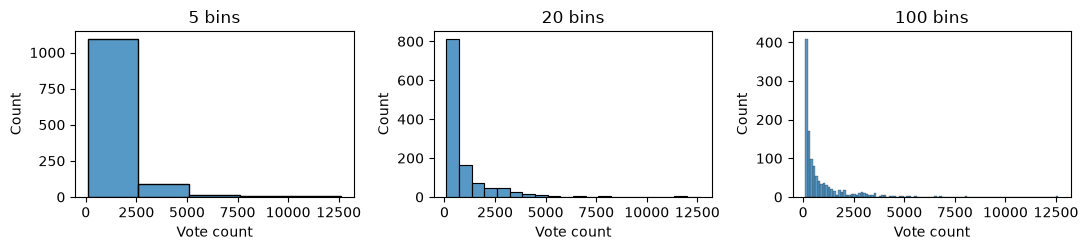

In [39]:
shown = movies_df["vote_count"]

titles = ["5 bins", "20 bins", "100 bins"]

fig, axes = plt.subplots(1, 3, figsize=(11, 2.6))

for ax, bins, title in zip(axes, (5, 20, 100), titles):
    sns.histplot(shown, bins=bins, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Vote count")

plt.tight_layout()
plt.show()

The `vote_count` distribution is strongly right-skewed. Most movies
have relatively few votes, while a small number of highly voted movies
form a long right tail.

This is also visible in the summary statistics, the mean vote count
(936.35) is much larger than the median (378), while the maximum reaches
12616 votes.

## 2.3 Credits Dataset

In [40]:
print("=== CREDITS DATASET ===")

print("\nShape:")
print(credits_df.shape)

print("\nColumns:")
print(credits_df.columns.tolist())

print("\nData types:")
print(credits_df.dtypes)

print("\nFirst rows:")
display(credits_df.head(10))

print("=== Missing Values Summary ===")
missing_credits = credits_df.isna().sum()
display(missing_credits[missing_credits > 0].rename_axis("column").reset_index(name="missing_count")
)

print("=== ROLE COUNTS ===")

display(credits_df["role"].value_counts().rename_axis("role").reset_index(name="count"))


=== CREDITS DATASET ===

Shape:
(14252, 7)

Columns:
['movie_id', 'person_id', 'person_name', 'role', 'department', 'job', 'billing_order']

Data types:
movie_id           int64
person_id          int64
person_name       object
role              object
department        object
job               object
billing_order    float64
dtype: object

First rows:


,movie_id,person_id,person_name,role,department,job,billing_order
0,755898,1634181,Rich Lee,director,Directing,Director,NaN
1,755898,23430,Timur Bekmambetov,producer,Production,Producer,NaN
2,755898,964093,Patrick Aiello,producer,Production,Producer,NaN
3,755898,1076356,Christopher Probst,cinematographer,Camera,Director of Photography,NaN
4,755898,9778,Ice Cube,actor,None,None,0.0
5,755898,52605,Eva Longoria,actor,None,None,1.0
6,755898,9048,Clark Gregg,actor,None,None,2.0
7,755898,1632530,Iman Benson,actor,None,None,3.0
8,755898,60482,Henry Hunter Hall,actor,None,None,4.0
9,755898,90498,Devon Bostick,actor,None,None,5.0


=== Missing Values Summary ===


,column,missing_count
0,department,7191
1,job,7191
2,billing_order,7061


=== ROLE COUNTS ===


,role,count
0,actor,7191
1,producer,4573
2,director,1289
3,cinematographer,1199


## 2.4 Missingness pattern

=== MISSING VALUES BY ROLE ===


,department,job,billing_order
role,,,
actor,7191,7191,0
cinematographer,0,0,1199
director,0,0,1289
producer,0,0,4573


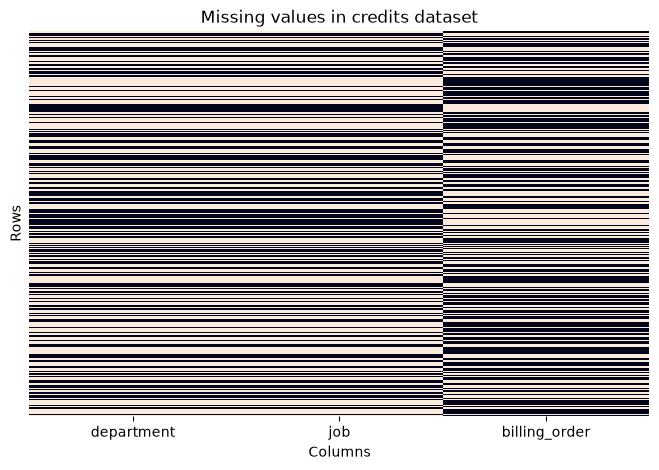

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
print("=== MISSING VALUES BY ROLE ===")

missing_by_role = (credits_df.groupby("role")[["department", "job", "billing_order"]].apply(lambda x: x.isna().sum()))

display(missing_by_role)

missing_cols = ["department", "job", "billing_order"]

plt.figure(figsize=(8, 5))

sns.heatmap(
    credits_df[missing_cols].isna(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing values in credits dataset")
plt.xlabel("Columns")
plt.ylabel("Rows")

plt.show()


- `department` and `job` each have 7191 missing values,
  exactly equal to the number of actor rows.
- `billing_order` has 7061 missing values,
  exactly equal to the number of non-actor rows.
- with the heatmap we see that  the missing values are structural and depend on the role so when billing_order is present department and job are null and if department is null then job is null and actor is present
- There are fewer than six actor rows per movie on average maximum:
  7191 actor rows versus 7248 expected if every movie had six actors.


In [42]:
##find mechanism
department_missing = credits_df["department"].isna()
job_missing = credits_df["job"].isna()
billing_missing = credits_df["billing_order"].isna()


print("=== Department missing by role ===")
print(pd.crosstab(credits_df["role"],department_missing,colnames=["missing"]))

print("\n=== Job missing by role ===")
print(pd.crosstab(credits_df["role"],job_missing,colnames=["missing"]))

print("\n=== Billing order missing by role ===")
print(pd.crosstab(credits_df["role"],billing_missing,colnames=["missing"]))


=== Department missing by role ===
missing          False  True 
role                         
actor                0   7191
cinematographer   1199      0
director          1289      0
producer          4573      0

=== Job missing by role ===
missing          False  True 
role                         
actor                0   7191
cinematographer   1199      0
director          1289      0
producer          4573      0

=== Billing order missing by role ===
missing          False  True 
role                         
actor             7191      0
cinematographer      0   1199
director             0   1289
producer             0   4573


- role = actor
→ department missing
→ job missing
→ billing_order present

- role = crew
→ department present
→ job present
→ billing_order missing

- the missing fields are determined by the observed role and correspond to attributes that are not applicable to that role so we are in the case of `MAR` mising at random

## 2.5 Finding impossible,ambigous and extreme values

In [43]:



release_date = pd.to_datetime(movies_df["release_date"],errors="coerce")


outside_period = ~release_date.between("2020-01-01","2025-12-31")

vote_below_threshold = movies_df["vote_count"] < 100

invalid_rating = ~movies_df["vote_average"].between(0,10)

duplicate_movie_ids = movies_df["id"].duplicated(keep=False)

empty_genres = movies_df["genre_ids"].apply(lambda x: len(x) == 0)


print("=== MOVIES: IMPOSSIBLE and  INVALID ===")

print("Release dates outside 2020-2025:",int(outside_period.sum()))

print("vote_count < 100:",int(vote_below_threshold.sum()))

print("vote_average outside [0, 10]:",int(invalid_rating.sum()))

print("Duplicated movie IDs:",int(duplicate_movie_ids.sum()))

print("Movies with empty genre list:",int(empty_genres.sum()))


print("\n=== CREDITS: INVALID and SUSPICIOUS ===")


allowed_roles = {"actor","director","producer","cinematographer"}

unknown_roles = ~credits_df["role"].isin(allowed_roles)

print("Unknown roles:",int(unknown_roles.sum()))

duplicate_credits = credits_df.duplicated(
    subset=["movie_id","person_id","role"],keep=False)

print("Duplicated (movie_id, person_id, role):",int(duplicate_credits.sum()))

=== MOVIES: IMPOSSIBLE and  INVALID ===
Release dates outside 2020-2025: 0
vote_count < 100: 0
vote_average outside [0, 10]: 0
Duplicated movie IDs: 0
Movies with empty genre list: 0

=== CREDITS: INVALID and SUSPICIOUS ===
Unknown roles: 0
Duplicated (movie_id, person_id, role): 0


`OUtliers `

In [44]:
Q1 = movies_df["vote_count"].quantile(0.25)
Q3 = movies_df["vote_count"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

vote_outliers = (
    (movies_df["vote_count"] < lower) |
    (movies_df["vote_count"] > upper)
)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower fence:", lower)
print("Upper fence:", upper)

print("Number of flagged movies:", vote_outliers.sum())
print(
    "Percentage:",
    round(vote_outliers.mean() * 100, 2),
    "%"
)

print("\n=== MOVIES: EXTREME VALUES ===")

print("Highest vote counts:")

display(movies_df.loc[vote_outliers,["title", "vote_count", "vote_average", "popularity"]].sort_values("vote_count",ascending=False).head(20))

Q1 = movies_df["popularity"].quantile(0.25)
Q3 = movies_df["popularity"].quantile(0.75)


Q1: 186.0
Q3: 1046.0
IQR: 860.0
Lower fence: -1104.0
Upper fence: 2336.0
Number of flagged movies: 131
Percentage: 10.84 %

=== MOVIES: EXTREME VALUES ===
Highest vote counts:


,title,vote_count,vote_average,popularity
2,Oppenheimer,12616,8.022,54.7098
5,The Batman,12609,7.671,44.3900
35,Soul,11785,8.087,24.1554
3,Top Gun: Maverick,11650,8.158,49.5341
51,Tenet,11590,7.172,22.4262
73,Don't Look Up,9741,7.053,17.7476
86,Luca,9149,7.772,17.2104
95,Bad Boys for Life,8910,7.105,17.5760
44,Nobody,8773,7.860,23.8408
13,John Wick: Chapter 4,8369,7.712,35.4990


In [45]:


IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

popularity_outliers = (
    (movies_df["popularity"] < lower) |
    (movies_df["popularity"] > upper)
)

print("Number of popularity outliers:", popularity_outliers.sum())
print(
    "Percentage:",
    round(popularity_outliers.mean() * 100, 2),
    "%"
)


print("Highest popularity values:")

display(movies_df.loc[popularity_outliers,["title", "vote_count", "vote_average", "popularity"]].sort_values("popularity",ascending=False).head(20))

Number of popularity outliers: 89
Percentage: 7.37 %
Highest popularity values:


,title,vote_count,vote_average,popularity
0,War of the Worlds,1160,4.034,107.0445
2,Oppenheimer,12616,8.022,54.7098
3,Top Gun: Maverick,11650,8.158,49.5341
1,False Positive,204,5.556,49.4602
4,The Housemaid,3163,7.251,48.9580
8,Sinners,5267,7.512,46.1146
5,The Batman,12609,7.671,44.3900
7,Karate Kid: Legends,1315,6.972,42.9390
6,F1,4769,7.826,42.8465
11,Mission: Impossible - The Final Reckoning,3208,7.171,40.5748


this highset  count movies for example movie with 12616 votes is extreme compared with the median 378 they appear with a small frequency

In [46]:
actors_per_movie = (credits_df[credits_df["role"] == "actor"].groupby("movie_id").size())

print("Movies with more than 6 actors:",int((actors_per_movie > 6).sum()))

print("Movies with exactly 6 actors:",int((actors_per_movie == 6).sum()))

print("Movies with fewer than 6 actors:",int((actors_per_movie < 6).sum()))


Movies with more than 6 actors: 0
Movies with exactly 6 actors: 1189
Movies with fewer than 6 actors: 14


having movies with less than 6 actors is unusual because the scope acquired to have the top 6 actors it's not an error just the API may returned few casts for that movies

## 2.6 Time patterns

release_date
2020    211
2021    225
2022    225
2023    202
2024    176
2025    169
Name: count, dtype: int64

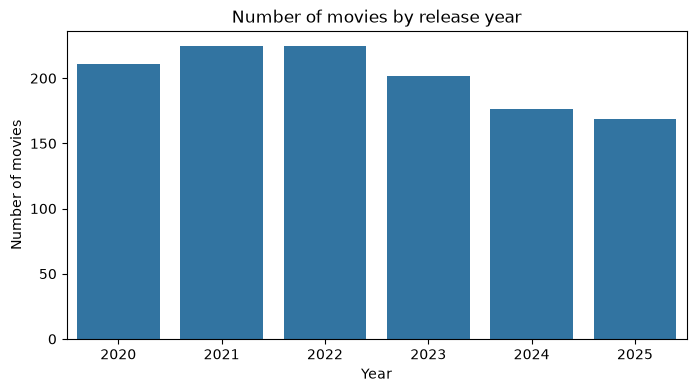

release_date
1      82
2      89
3     105
4      84
5      71
6      81
7      96
8     116
9     143
10    135
11    100
12    106
Name: movie_count, dtype: int64

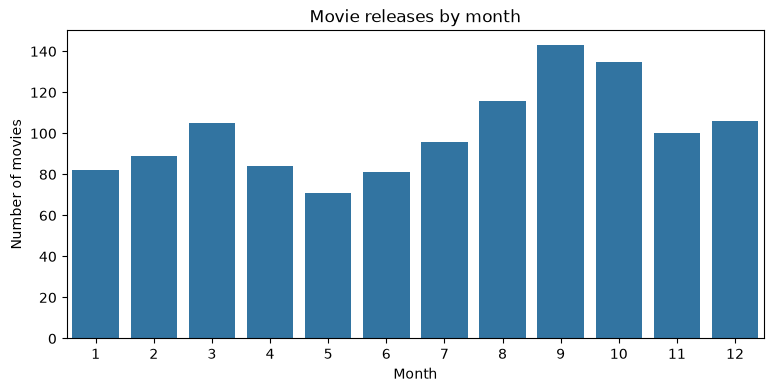

Missing months: PeriodIndex([], dtype='period[M]')


In [47]:
release_date = pd.to_datetime(movies_df["release_date"], errors="coerce")

movies_by_year = (release_date.dt.year.value_counts().sort_index())

display(movies_by_year)
plt.figure(figsize=(8, 4))

sns.barplot(x=movies_by_year.index,y=movies_by_year.values)

plt.title("Number of movies by release year")
plt.xlabel("Year")
plt.ylabel("Number of movies")

plt.show()

movies_by_month = (release_date.dt.month.value_counts().sort_index())

display(movies_by_month.rename("movie_count"))

plt.figure(figsize=(9, 4))

sns.barplot(x=movies_by_month.index,y=movies_by_month.values)

plt.title("Movie releases by month")
plt.xlabel("Month")
plt.ylabel("Number of movies")

plt.show()

## to know if threre are any missing months in the dataset from 2020 to 2025
movies_by_period = (
    release_date
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

full_period = pd.period_range(
    "2020-01",
    "2025-12",
    freq="M"
)

missing_months = full_period.difference(
    movies_by_period.index
)

print("Missing months:", missing_months)

The dataset covers all years from 2020 to 2025.

The annual number of selected movies is relatively stable from 2020
to 2022, with 211 movies in 2020 and 225 in both 2021 and 2022.
The number then decreases to 202 movies in 2023, 176 in 2024 and
169 in 2025.

The monthly distribution is also not uniform. September has the
largest number of selected releases (143), followed by October (135),
while May has the lowest count (71).

## 3. Cleaning

In [51]:
movies_clean = movies_df.copy()
credits_clean = credits_df.copy()
DECISIONS = []

## convert release_date to datetime format insteas of object
movies_clean["release_date"] = pd.to_datetime(movies_clean["release_date"],errors="coerce")
print(movies_clean["release_date"].isna().sum())

DECISIONS.append(("convert release_date","needed for chronological analysis",len(movies_clean)))
credits_clean.duplicated(subset=["movie_id", "person_id", "role"]).sum() ## it's 0 so no duplicates and no action to dod 

DECISIONS.append((
    "There is no impossible movies so there is no need to remove any movies",
    "release date, vote threshold or rating violates acquisition rules",
    
))


structural_missing = (
    credits_clean["department"].isna()
    | credits_clean["job"].isna()
    | credits_clean["billing_order"].isna()
)

DECISIONS.append((
    "keep structural missing values",
    "missingness is determined by role and means not applicable",
    int(structural_missing.sum())
))


0


In [52]:

actor_count = (credits_clean[credits_clean["role"] == "actor"].groupby("movie_id").size())

movies_clean["actor_count"] = (movies_clean["id"].map(actor_count).fillna(0).astype(int))

movies_clean["less_than_6_actors"] = (movies_clean["actor_count"] < 6)
DECISIONS.append((
    "flag movies with fewer than 6 actors",
    "fewer than 6 actors is unusual but can be valid in TMDB",
    int(movies_clean["less_than_6_actors"].sum())
))



for role in [
    "director",
    "producer",
    "cinematographer"
]:

    ids = credits_clean.loc[credits_clean["role"] == role,"movie_id"].unique()
    movies_clean[f"has_{role}"] = (movies_clean["id"].isin(ids))

movies_clean["complete_selected_credits"] = (
    ~movies_clean["less_than_6_actors"]
    & movies_clean["has_director"]
    & movies_clean["has_producer"]
    & movies_clean["has_cinematographer"]
)
DECISIONS.append((
    "flag incomplete selected credits",
    "some movies may not contain all roles required for collaboration analysis",
    int((~movies_clean["complete_selected_credits"]).sum())
))

display(movies_clean.head())



,id,title,original_title,release_date,genre_ids,original_language,vote_count,vote_average,popularity,actor_count,less_than_6_actors,has_director,has_producer,has_cinematographer,complete_selected_credits
0,755898,War of the Worlds,War of the Worlds,2025-07-29,"[878, 53]",en,1160,4.034,107.0445,6,False,True,True,True,True
1,591634,False Positive,False Positive,2021-06-18,"[27, 9648, 53]",en,204,5.556,49.4602,6,False,True,True,True,True
2,872585,Oppenheimer,Oppenheimer,2023-07-19,"[18, 36]",en,12616,8.022,54.7098,6,False,True,True,True,True
3,361743,Top Gun: Maverick,Top Gun: Maverick,2022-05-21,"[28, 18]",en,11650,8.158,49.5341,6,False,True,True,True,True
4,1368166,The Housemaid,The Housemaid,2025-12-18,"[9648, 53]",en,3163,7.251,48.9580,6,False,True,True,True,True


## 4. Clustering


## Clustering objective

One row represents one movie
Our objective is to identify groups of movies with similar profiles based on
their release period, audience engagement, rating, popularity and genres.



# 4.Movie Clustering

## 4.1 Clustering objective


**One row represents one film.**

Our objective is to discover groups of movies with similar profiles according
to:

- release period;
- audience engagement;
- audience rating;
- popularity;
- genre composition.


The clustering features will be derived from:

- `release_date` → `year`;
- `vote_count` → `log_vote_count` (because right skewed so using their values would give very large observations a
strong influence on distance calculations );
- `vote_average`;
- `popularity` → `log_popularity` (\[
x' = \log(1+x)
\]
);
- `genre_ids` → multi-hot genre indicators.




Identifiers and descriptive text such as `id`, `title` and `original_title`
are kept only to interpret the clusters later and we will not use them as clustering
features.

In [61]:
movies = movies_clean.copy()

# Release year
movies["year"] = movies["release_date"].dt.year

# Log transformations for right-skewed variables
movies["log_vote_count"] = np.log1p(movies["vote_count"])

movies["log_popularity"] = np.log1p(movies["popularity"])


In [ ]:
## multi-hot encoding genres
all_genres = sorted({genre
    for genres in movies["genre_ids"]
    for genre in genres
})

print("Number of distinct genres:", len(all_genres))
print("Genre IDs:", all_genres)

Number of distinct genres: 19
Genre IDs: [12, 14, 16, 18, 27, 28, 35, 36, 37, 53, 80, 99, 878, 9648, 10402, 10749, 10751, 10752, 10770]


In [69]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()

genre_matrix = mlb.fit_transform(
    movies["genre_ids"]
)

genre_df = pd.DataFrame(genre_matrix,columns=[f"genre_{genre}"for genre in mlb.classes_], index=movies.index)


cols_feat = [
    "year",
    "log_vote_count",
    "vote_average",
    "log_popularity"
]

feat = movies[cols_feat].copy()
Xt = (feat - feat.mean()) / feat.std()

## final matrix of features
X_df = pd.concat([Xt,genre_df],axis=1)

display(X_df)



,year,log_vote_count,vote_average,log_popularity,genre_12,genre_14,genre_16,genre_18,genre_27,genre_28,...,genre_53,genre_80,genre_99,genre_878,genre_9648,genre_10402,genre_10749,genre_10751,genre_10752,genre_10770
0,1.594053,0.818019,-3.343350,4.812021,0,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,0
1,-0.805468,-0.753558,-1.241064,3.447049,0,0,0,0,1,0,...,1,0,0,0,1,0,0,0,0,0
2,0.394292,2.980276,2.165137,3.624485,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,-0.205588,2.908085,2.352990,3.449672,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1.594053,1.726652,1.100182,3.429116,0,0,0,0,0,0,...,1,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1203,-1.405349,-0.706187,0.339104,-2.023309,0,0,1,1,0,0,...,0,0,0,0,0,0,0,1,0,0
1204,-1.405349,-0.685446,1.029737,-2.128176,0,1,1,1,0,0,...,0,0,0,0,0,0,1,1,0,0
1205,-0.805468,-0.681354,-2.009048,-2.013944,0,0,0,0,1,1,...,1,0,0,1,0,0,0,0,0,0
1206,-1.405349,-1.246492,0.339104,-2.198010,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


In [74]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []
cluster_sizes = {}

for k in range(2, 9):

    km = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=0
    )

    labels = km.fit_predict(Xt)

    # Evaluation metrics
    inertia = km.inertia_
    silhouette = silhouette_score(Xt, labels)

    # Number of movies in each cluster
    sizes = pd.Series(labels).value_counts().sort_index()

    cluster_sizes[k] = sizes

    results.append({
        "k": k,
        "inertia": inertia,
        "silhouette": silhouette,
        "smallest_cluster": sizes.min(),
        "largest_cluster": sizes.max()
    })

results_df = pd.DataFrame(results)

display(
    results_df.round({
        "inertia": 2,
        "silhouette": 3
    })
)

,k,inertia,silhouette,smallest_cluster,largest_cluster
0,2,3091.24,0.324,468,740
1,3,2428.64,0.276,367,460
2,4,2009.28,0.268,225,349
3,5,1768.58,0.253,161,346
4,6,1587.18,0.243,126,256
5,7,1447.47,0.239,106,217
6,8,1321.78,0.244,87,215


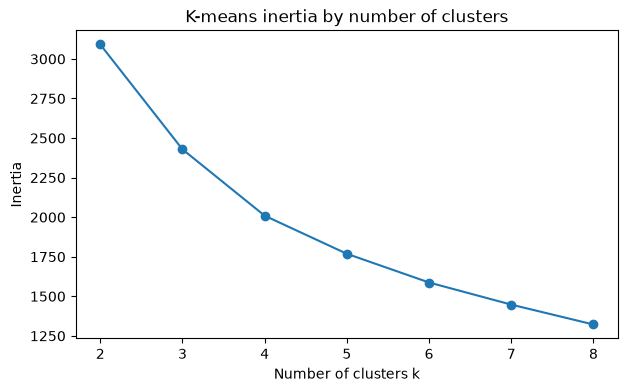

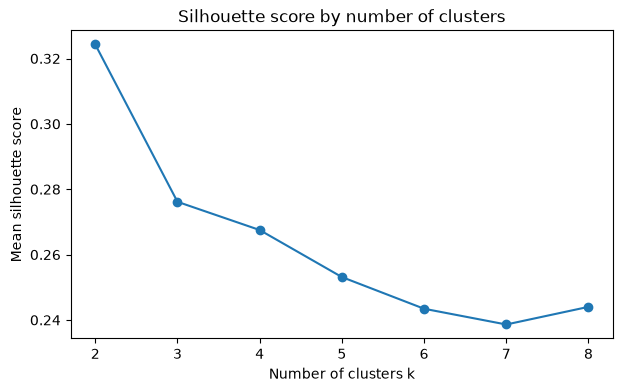

In [76]:
plt.figure(figsize=(7, 4))

plt.plot(
    results_df["k"],
    results_df["inertia"],
    marker="o"
)

plt.xlabel("Number of clusters k")
plt.ylabel("Inertia")
plt.title("K-means inertia by number of clusters")

plt.xticks(results_df["k"])

plt.show()


plt.figure(figsize=(7, 4))

plt.plot(
    results_df["k"],
    results_df["silhouette"],
    marker="o"
)

plt.xlabel("Number of clusters k")
plt.ylabel("Mean silhouette score")
plt.title("Silhouette score by number of clusters")

plt.xticks(results_df["k"])

plt.show()

### candidate values of k

we see that the inertia decreases continuously as the number of clusters increases,
as expected. There is no sharp elbow. However, the reduction in inertia
becomes progressively smaller after approximately \(k=3\) to \(k=4\).

The silhouette score is highest for \(k=2\) (0.324), indicating the
strongest geometric separation. It decreases to 0.276 for \(k=3\) and
0.268 for \(k=4\).

However,as we see in the lecture  the silhouette score is used only as a diagnostic so a higher
silhouette indicates compact and separated clusters, but does not guarantee
that the groups are the most meaningful for interpretation.


Therefore, \(k=2\), \(k=3\), and \(k=4\) are retained as candidate
solutions. Their cluster profiles and actual movie rows will be inspected
before selecting the final number of clusters.

so we should see the clusters tio interpret what kind of films are inside in each cluster

In [80]:
candidate_models = {}

for k in [2, 3, 4]:

    km = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=0
    )

    labels = km.fit_predict(Xt)

    candidate_models[k] = labels


for k, labels in candidate_models.items():

    temp = movies.copy()
    temp["cluster"] = labels

    profile = (
        temp.groupby("cluster")[ ["year","vote_count","vote_average","popularity"]].mean().round(2)
    )

    profile["n"] = (
        temp.groupby("cluster").size()
    )

    print(f"\n k = {k}")

    display(profile)


 k = 2


,year,vote_count,vote_average,popularity,n
cluster,,,,,
0,2022.57,1968.18,6.92,13.12,468
1,2022.20,283.79,6.16,4.55,740



 k = 3


,year,vote_count,vote_average,popularity,n
cluster,,,,,
0,2023.98,323.40,6.40,6.34,381
1,2022.25,2340.62,6.97,14.24,367
2,2021.07,323.68,6.08,4.05,460



 k = 4


,year,vote_count,vote_average,popularity,n
cluster,,,,,
0,2021.29,237.47,5.80,3.80,347
1,2024.09,334.02,6.41,6.49,349
2,2022.96,2950.69,7.01,18.33,225
3,2021.01,934.61,6.87,6.28,287


- The k=2 solution has the highest silhouette score, but mainly separates
high-engagement films from lower-engagement films, which is a rather coarse
partition.
-  k=3 introduces a useful temporal distinction between newer
and older lower-engagement films while preserving a separate high-engagement
group.
- The k=4 solution provides the richest interpretable structure while
keeping reasonably balanced cluster sizes. It separates:

   - older low-engagement / lower-rated films;
   - recent moderate-engagement films;
   - high-profile, highly voted and highly popular films;
   - older well-rated films with moderate-to-high engagement.

Therefore, we select \(k=4\) as the current best candidate.

In [90]:
k_final = 4

km_final = KMeans(
    n_clusters=k_final,
    init="k-means++",
    n_init=10,
    random_state=0
)

movies["cluster"] = km_final.fit_predict(Xt)
movies["cluster"].value_counts().sort_index()
genre_profile = genre_df.copy()

genre_profile["cluster"] = movies["cluster"]

genre_cluster_profile = (genre_profile.groupby("cluster").mean().round(3))
display(genre_cluster_profile)

for cluster in range(k_final):

    top_genres = (
        genre_cluster_profile
        .loc[cluster]
        .sort_values(ascending=False)
        .head(6)
    )

    print(f"\nCluster {cluster}")
    display(
        top_genres
        .rename("proportion")
        .to_frame()
    )

,genre_12,genre_14,genre_16,genre_18,genre_27,genre_28,genre_35,genre_36,genre_37,genre_53,genre_80,genre_99,genre_878,genre_9648,genre_10402,genre_10749,genre_10751,genre_10752,genre_10770
cluster,,,,,,,,,,,,,,,,,,,
0,0.035,0.035,0.009,0.510,0.274,0.282,0.164,0.026,0.023,0.648,0.207,0.006,0.075,0.187,0.006,0.092,0.017,0.014,0.035
1,0.043,0.029,0.011,0.628,0.186,0.249,0.209,0.083,0.020,0.536,0.160,0.006,0.074,0.097,0.037,0.129,0.023,0.032,0.006
2,0.076,0.049,0.022,0.542,0.200,0.271,0.182,0.084,0.004,0.573,0.204,0.000,0.098,0.111,0.031,0.133,0.018,0.040,0.004
3,0.031,0.042,0.024,0.749,0.122,0.139,0.160,0.111,0.024,0.355,0.136,0.010,0.070,0.105,0.052,0.174,0.063,0.042,0.007



Cluster 0


,proportion
genre_53,0.648
genre_18,0.510
genre_28,0.282
genre_27,0.274
genre_80,0.207
genre_9648,0.187



Cluster 1


,proportion
genre_18,0.628
genre_53,0.536
genre_28,0.249
genre_35,0.209
genre_27,0.186
genre_80,0.160



Cluster 2


,proportion
genre_53,0.573
genre_18,0.542
genre_28,0.271
genre_80,0.204
genre_27,0.200
genre_35,0.182



Cluster 3


,proportion
genre_18,0.749
genre_53,0.355
genre_10749,0.174
genre_35,0.160
genre_28,0.139
genre_80,0.136


### Inspecting movies inside each cluster

For each cluster we inspect:

- the most-voted movies;
- the most-popular movies;

In [94]:
cols_detail = [
    "title",
    "year",
    "genre_ids",
    "vote_count",
    "vote_average",
    "popularity"
]

for cluster in range(k_final):

    print(f"\n===== Cluster {cluster}: most voted =====")

    display(
        movies.loc[
            movies["cluster"] == cluster,
            cols_detail
        ]
        .sort_values(
            "vote_count",
            ascending=False
        )
        .head(10)
    )





===== Cluster 0: most voted =====


,title,year,genre_ids,vote_count,vote_average,popularity
472,The Rental,2020,"[27, 53]",1029,5.548,5.4710
662,Mother/Android,2021,"[878, 53]",866,5.749,5.7603
542,White Noise,2022,"[35, 18]",842,5.600,5.9492
1076,Intrusion,2021,"[18, 9648, 53]",780,5.950,3.4196
1071,Lost Girls,2020,"[18, 9648, 53, 36]",774,6.064,3.2997
811,Prisoners of the Ghostland,2021,"[28, 14, 53, 37, 27]",689,4.983,4.8021
877,Bliss,2021,"[878, 10749, 18]",685,5.508,4.4715
892,Persuasion,2022,"[10749, 18, 35]",683,6.083,4.5746
1048,Aftermath,2021,"[27, 80, 18, 53]",679,6.200,3.2130
487,The Rhythm Section,2020,"[28, 53]",678,5.520,6.9433



===== Cluster 1: most voted =====


,title,year,genre_ids,vote_count,vote_average,popularity
327,Havoc,2025,"[28, 80, 53, 18]",1351,6.398,9.3061
172,Flight Risk,2025,"[28, 53]",1243,5.903,12.5252
359,Spaceman,2024,"[878, 12, 18]",1127,6.690,8.3912
377,Woman of the Hour,2024,"[80, 18, 53]",1114,6.387,8.0878
212,Wolf Man,2025,"[27, 53]",1074,6.124,10.9060
368,Don't Move,2024,"[27, 53]",1072,6.320,7.5204
233,Megalopolis,2024,"[878, 18, 14]",1066,5.149,9.5676
312,Elevation,2024,"[28, 878, 53]",1065,6.400,9.0846
341,Bob Marley: One Love,2024,"[10402, 36, 18]",1022,6.600,8.0584
295,Silent Night,2023,"[28, 53, 80, 18]",990,6.137,9.4791



===== Cluster 2: most voted =====


,title,year,genre_ids,vote_count,vote_average,popularity
2,Oppenheimer,2023,"[18, 36]",12616,8.022,54.7098
5,The Batman,2022,"[80, 9648, 53]",12609,7.671,44.3900
35,Soul,2020,"[16, 10751, 18, 10402, 14]",11785,8.087,24.1554
3,Top Gun: Maverick,2022,"[28, 18]",11650,8.158,49.5341
51,Tenet,2020,"[28, 53, 878]",11590,7.172,22.4262
73,Don't Look Up,2021,"[35, 878, 18]",9741,7.053,17.7476
86,Luca,2021,"[16, 10751, 14, 18, 35]",9149,7.772,17.2104
95,Bad Boys for Life,2020,"[53, 28, 80]",8910,7.105,17.5760
44,Nobody,2021,"[28, 53]",8773,7.860,23.8408
13,John Wick: Chapter 4,2023,"[28, 53, 80]",8369,7.712,35.4990



===== Cluster 3: most voted =====


,title,year,genre_ids,vote_count,vote_average,popularity
236,Promising Young Woman,2020,"[53, 80, 18]",3871,7.369,10.1624
272,The Devil All the Time,2020,"[80, 18, 53]",3794,7.169,9.3039
435,The Trial of the Chicago 7,2020,"[18, 36]",3464,7.654,7.5782
302,The Guilty,2021,"[18, 53]",3280,6.425,9.2891
315,Project Power,2020,"[28, 80, 878, 53]",3160,6.418,8.6347
483,All the Bright Places,2020,"[10749, 18]",3078,7.638,6.5227
402,Run,2020,"[53, 27, 18]",2995,7.200,8.1562
342,Sound of Metal,2020,"[18, 10402]",2971,7.707,8.4795
248,Ava,2020,"[28, 53, 80]",2815,5.829,10.3427
445,Unhinged,2020,"[28, 53, 27]",2600,6.427,7.3746


In [95]:
for cluster in range(k_final):

    print(f"\n===== Cluster {cluster}: most popular =====")

    display(
        movies.loc[
            movies["cluster"] == cluster,
            cols_detail
        ]
        .sort_values(
            "popularity",
            ascending=False
        )
        .head(10)
    )


===== Cluster 0: most popular =====


,title,year,genre_ids,vote_count,vote_average,popularity
203,Run Sweetheart Run,2020,"[27, 53]",238,5.536,9.4833
320,13 Minutes,2021,"[28, 18, 53]",308,5.800,8.6340
365,The Misfits,2021,"[28, 53]",535,5.400,7.9929
407,Force of Nature,2020,"[28, 80, 53]",578,5.130,7.4901
433,SAS: Red Notice,2021,"[18, 28, 53]",616,5.826,7.3078
389,Paradise Highway,2022,"[53, 80, 18]",215,5.874,7.2203
490,The Doorman,2020,"[28, 53]",483,5.771,7.1422
487,The Rhythm Section,2020,"[28, 53]",678,5.520,6.9433
455,Black Site,2022,"[28, 53, 80, 18]",300,6.023,6.8591
412,The Tax Collector,2020,"[28, 80, 18]",575,5.739,6.8498



===== Cluster 1: most popular =====


,title,year,genre_ids,vote_count,vote_average,popularity
83,Another Simple Favor,2025,"[35, 53, 9648]",564,5.792,16.4476
108,The Threesome,2025,"[35, 10749, 18]",126,6.333,15.2640
97,I Know What You Did Last Summer,2025,"[27, 53, 9648]",893,5.595,14.9774
139,David,2025,"[16, 10751, 18, 36, 12]",200,8.000,14.7193
128,Die My Love,2025,[18],660,6.100,14.7061
98,Blue Moon,2025,"[10402, 36, 18, 35]",338,6.635,14.4989
138,After the Hunt,2025,[18],531,5.672,13.8937
126,Highest 2 Lowest,2025,"[53, 80, 18]",543,5.479,13.6374
200,The Strangers: Chapter 2,2025,"[27, 53]",406,6.030,13.2454
153,Clown in a Cornfield,2025,"[27, 9648, 53]",629,6.083,13.1157



===== Cluster 2: most popular =====


,title,year,genre_ids,vote_count,vote_average,popularity
0,War of the Worlds,2025,"[878, 53]",1160,4.034,107.0445
2,Oppenheimer,2023,"[18, 36]",12616,8.022,54.7098
3,Top Gun: Maverick,2022,"[28, 18]",11650,8.158,49.5341
1,False Positive,2021,"[27, 9648, 53]",204,5.556,49.4602
4,The Housemaid,2025,"[9648, 53]",3163,7.251,48.9580
8,Sinners,2025,"[27, 28, 53]",5267,7.512,46.1146
5,The Batman,2022,"[80, 9648, 53]",12609,7.671,44.3900
7,Karate Kid: Legends,2025,"[28, 12, 18]",1315,6.972,42.9390
6,F1,2025,"[28, 18]",4769,7.826,42.8465
11,Mission: Impossible - The Final Reckoning,2025,"[28, 53, 12]",3208,7.171,40.5748



===== Cluster 3: most popular =====


,title,year,genre_ids,vote_count,vote_average,popularity
157,The Banker,2020,[18],1164,7.630,13.3522
168,Honest Thief,2020,"[53, 28, 80]",1954,6.458,12.8453
179,Wrong Turn,2021,"[27, 53]",1403,5.955,12.8113
217,She Said,2022,"[18, 36]",757,7.160,11.4822
221,Swan Song,2021,"[18, 878]",623,7.100,10.7578
246,The Fallout,2021,[18],1338,7.487,10.6118
209,No Sudden Move,2021,"[80, 53]",848,6.375,10.5883
251,The Craft: Legacy,2020,"[27, 18, 14]",918,6.105,10.5197
250,The Marksman,2021,"[28, 18, 53]",1786,6.760,10.4542
248,Ava,2020,"[28, 53, 80]",2815,5.829,10.3427


## Cluster interpretation

| Cluster | Name | Interpretation |
|---|---|---|
| **Cluster 0** | **Low-engagement, lower-rated thriller-oriented films** | Mostly Thriller and Drama movies, with relatively high shares of Horror, Action and Crime. This cluster has the lowest average vote count, rating and popularity of the four clusters. |
| **Cluster 1** | **Recent moderate-engagement drama/thriller releases** | Mainly recent releases, with an average year close to 2024. Movies have moderate vote counts, ratings and popularity, and are primarily Drama and Thriller films. |
| **Cluster 2** | **High-profile, high-engagement films** | Contains the most visible and highly engaged-with movies. It has by far the highest average vote count and popularity, as well as the highest average rating. Examples include *Oppenheimer*, *The Batman*, *Top Gun: Maverick* and *Tenet*. |
| **Cluster 3** | **Older, well-rated drama-oriented films** | Mainly earlier releases with relatively high ratings and moderate-to-high audience engagement. Drama is particularly dominant, representing approximately 75% of the movies in this cluster. |